# Longitudinal risk, heterogeneity and the frozen next study

**Question:** Is elevated predicted risk persistent or increasing as injury approaches, and do findings survive reasonable checks? Matched plots are descriptive development comparisons, not a new independent validation.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/injury_analysis').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_dynamic_common import OUT, CACHE, read_table, valid_checkpoint
pd.set_option('display.max_columns', 20)
def show(name, **kwargs):
    display(read_table(name).head(kwargs.get('rows', 30)))
def plot(name):
    display(Image(filename=str(OUT / 'figures' / (name + '.png')), width=1100))


In [2]:
from src.injury_analysis.ucl_dynamic_robustness import run_robustness
from src.injury_analysis.ucl_dynamic_trajectories import run_trajectories
run_robustness();run_trajectories()
matches=read_table('matched_controls')
display(matches.groupby('origin').size().rename('matched_events'))

origin
new same-strata match              20
reused original matched control    22
Name: matched_events, dtype: int64

Existing matched controls are preserved. Newly eligible events receive same-stratum matches only when necessary. Case/control windows use no control appearances after its index outing. Complete balanced support is required across all five outings or all four calendar bins. Uncertainty resamples connected sets sharing either a case or control pitcher. No smoothed curve or forced injury phenotype is used.

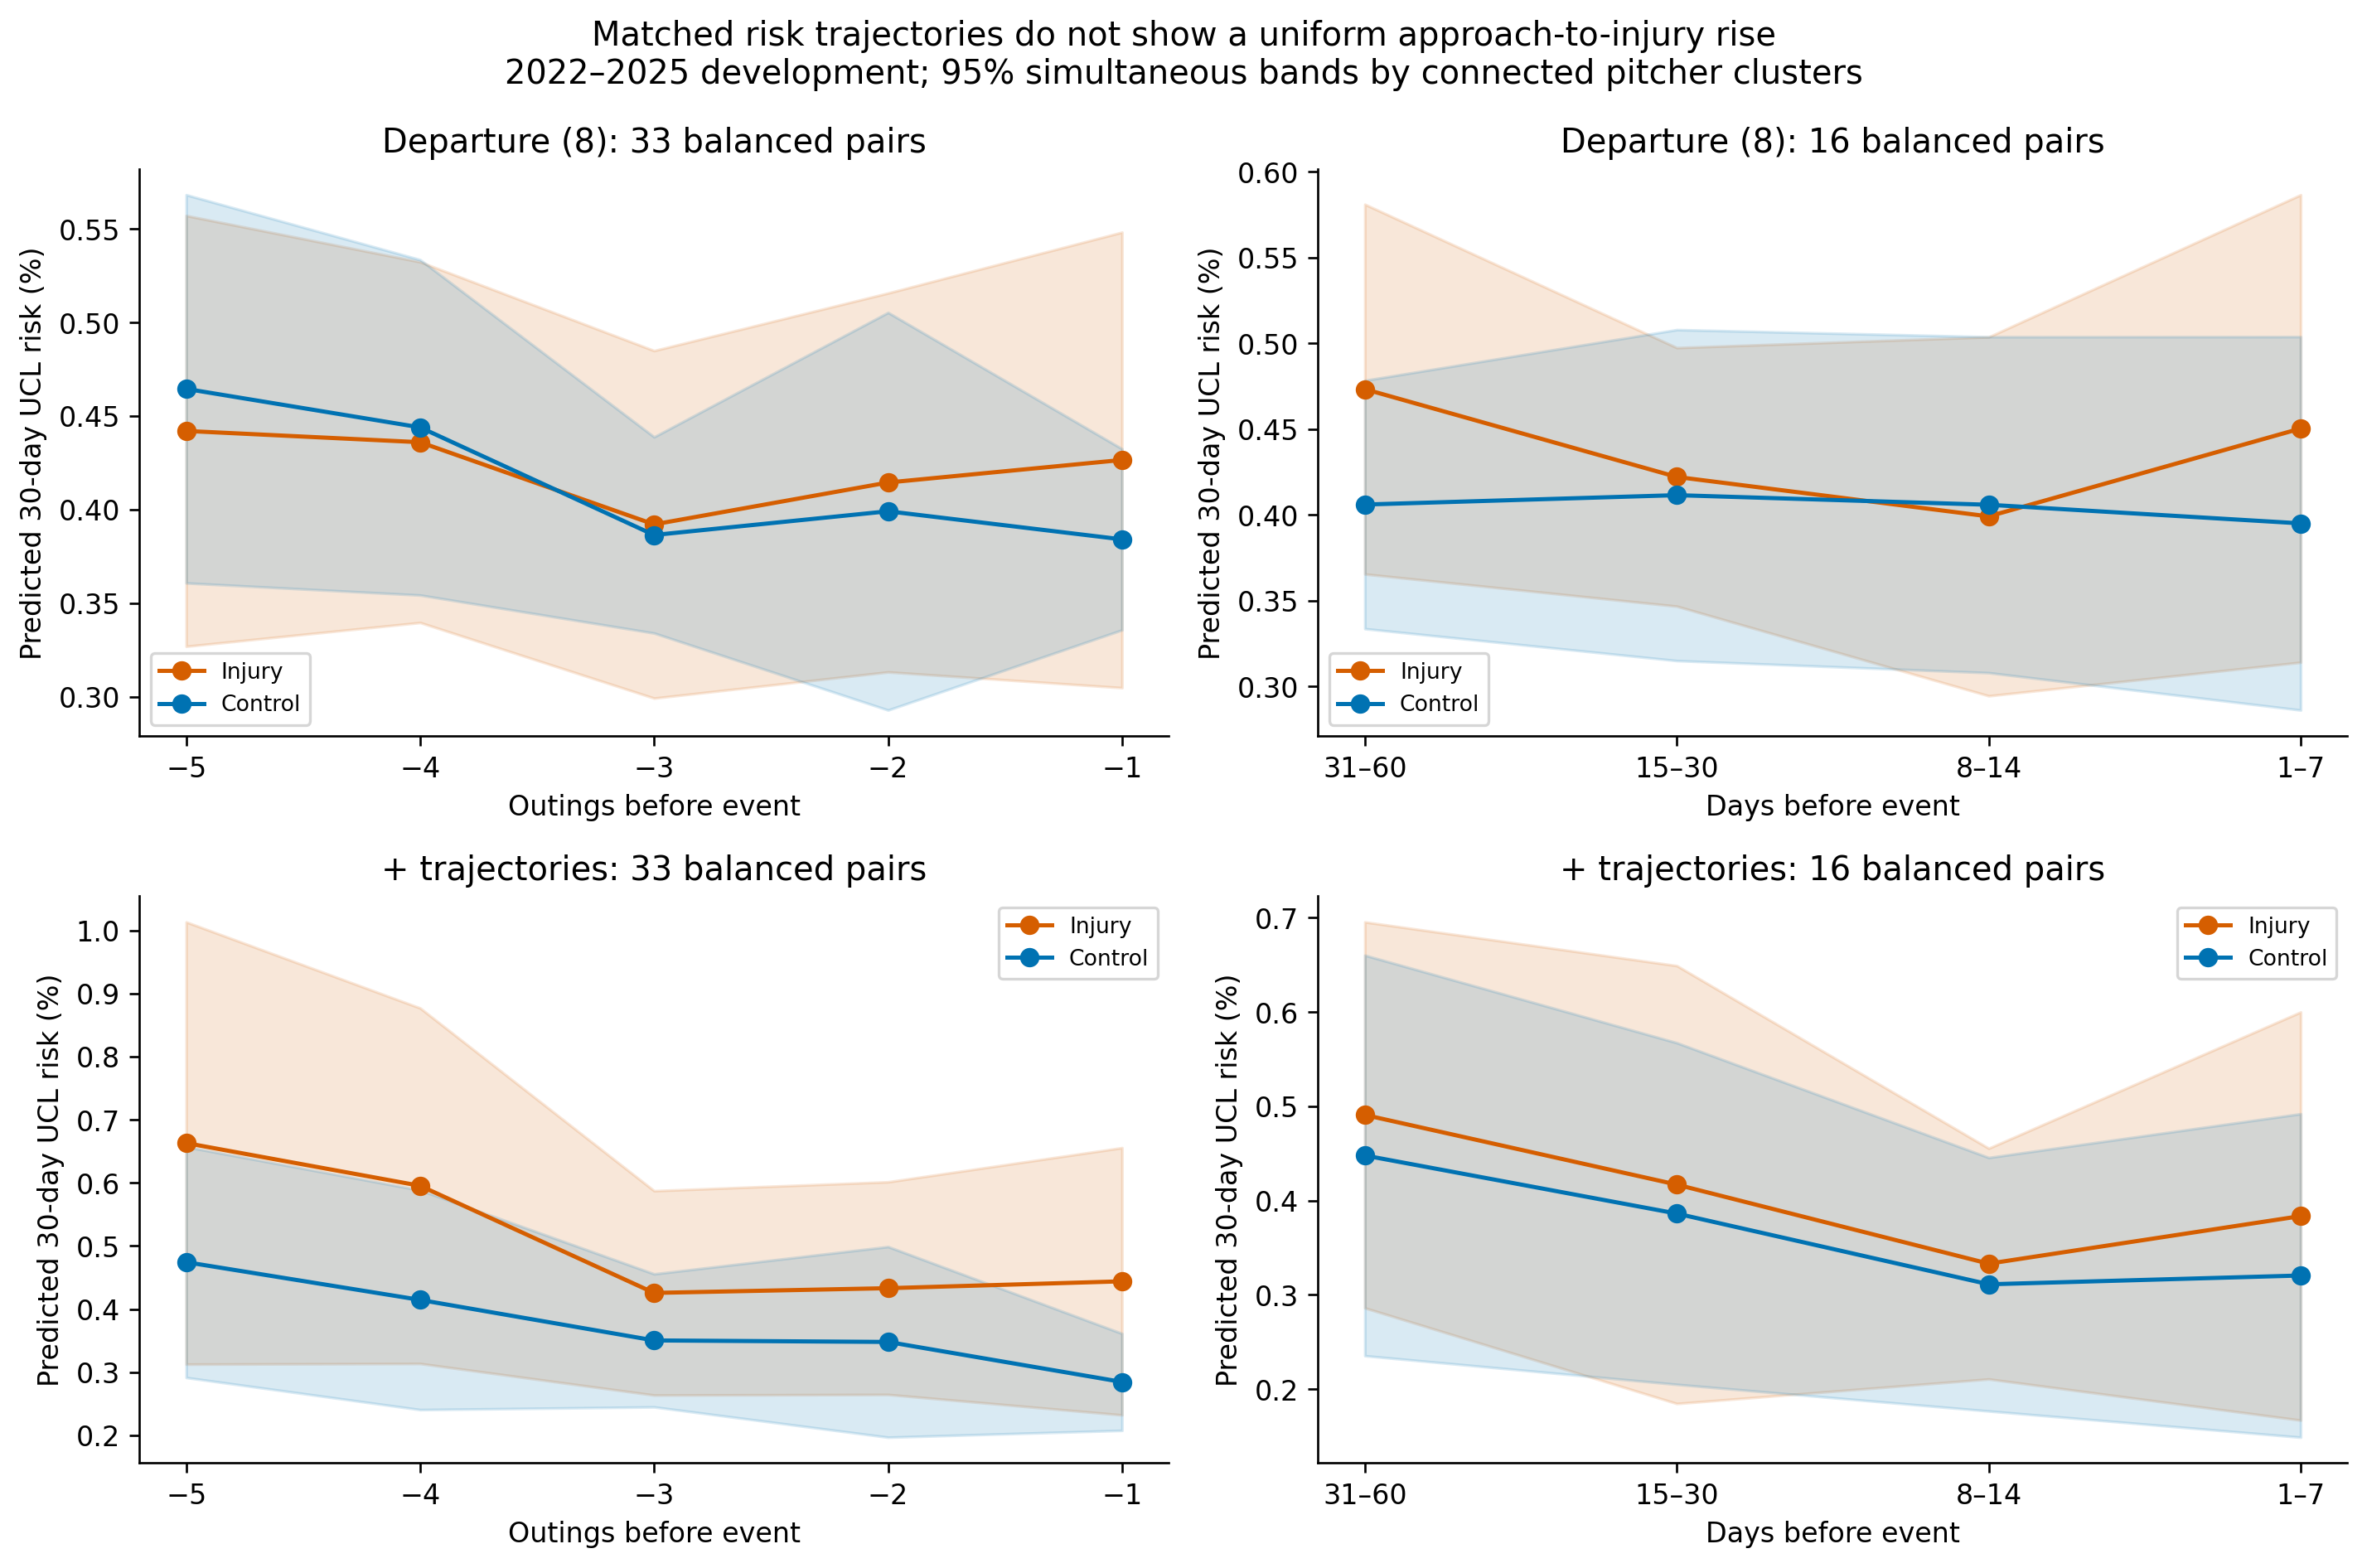

,model,mode,partition,kind,events,mean_offset,last_minus_first,change_ci_low,change_ci_high,fraction_events_rising
2,Profile,outings,combined,difference,33,0.000590,0.000123,-0.000048,0.000313,0.484848
11,Profile,calendar,combined,difference,16,0.000227,-0.000061,-0.000196,0.000085,0.375000
20,Departure,outings,combined,difference,33,0.000066,0.000649,-0.000801,0.002198,0.606061
29,Departure,calendar,combined,difference,16,0.000316,-0.000120,-0.001166,0.000846,0.437500
38,Profile + departure,outings,combined,difference,33,0.000798,0.000567,-0.001155,0.002199,0.606061
47,Profile + departure,calendar,combined,difference,16,0.000155,0.000132,-0.001046,0.001387,0.437500
56,Profile + departure + trajectory,outings,combined,difference,33,0.001378,-0.000293,-0.002964,0.002893,0.545455
65,Profile + departure + trajectory,calendar,combined,difference,16,0.000397,0.000200,-0.001067,0.001561,0.500000


In [3]:
plot('04_matched_risk_trajectories')
s=read_table('risk_trajectory_shapes')
display(s.loc[s.partition.eq('combined')&s.kind.eq('difference')])

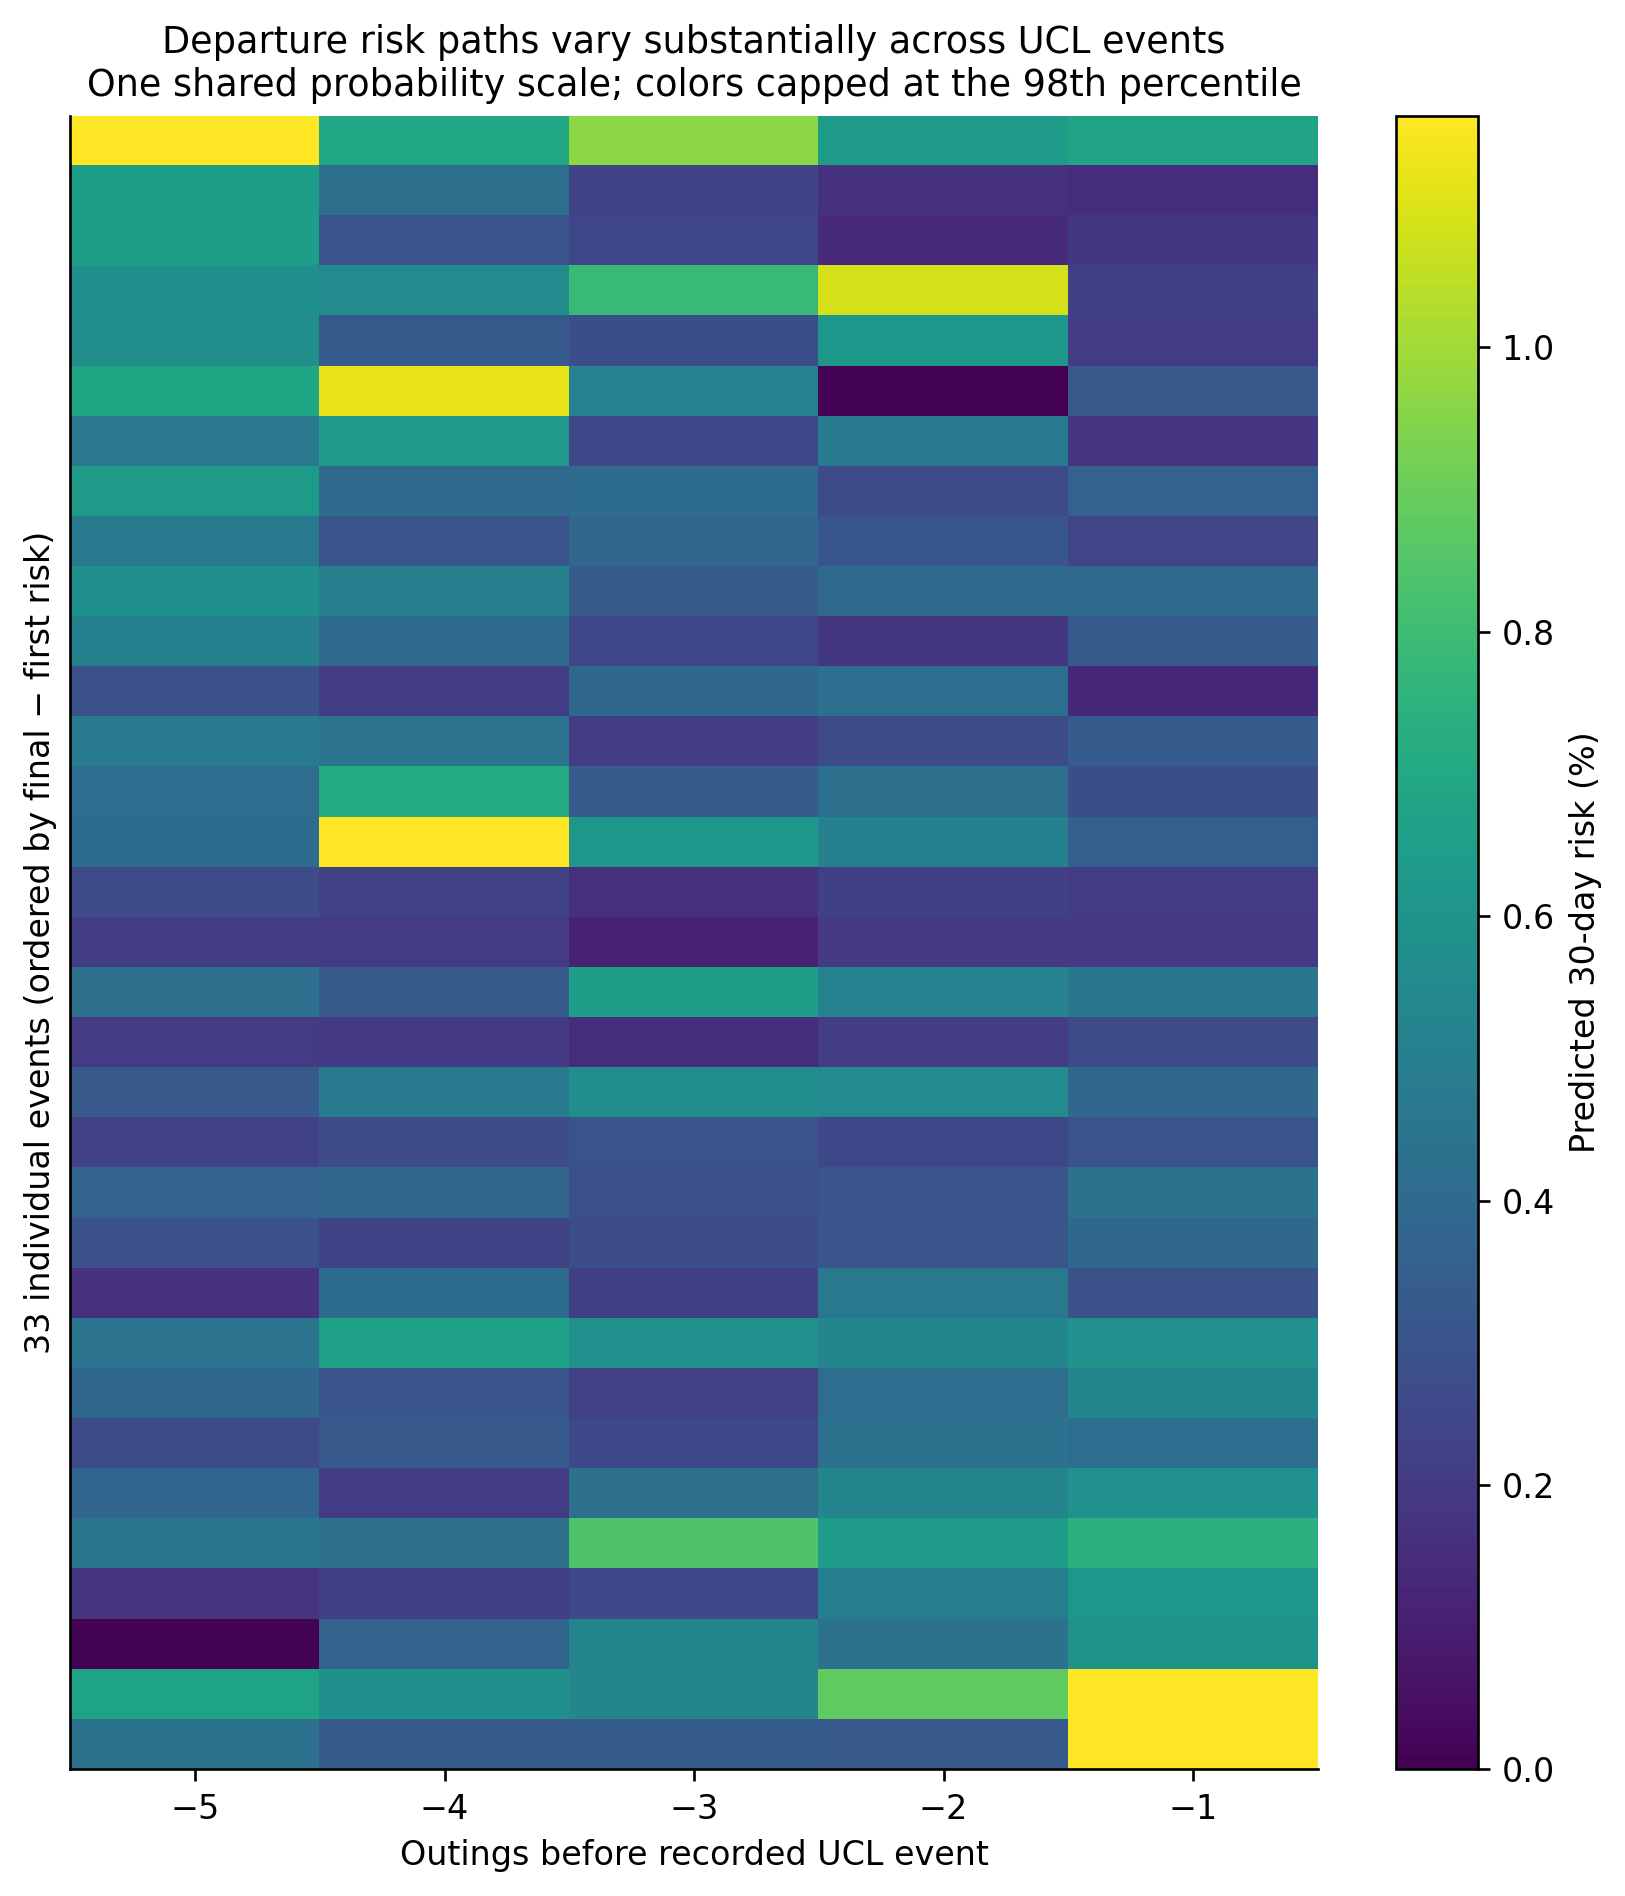

In [4]:
plot('05_individual_risk_heterogeneity')

**Findings:** The five-outing plots contain 33 balanced events; calendar plots contain 16. Case-control change intervals cross zero. Departure risk does not rise consistently toward injury. Individual paths vary substantially. Persistent offsets cannot be interpreted as injury imminence, and risk scores are not physiological measurements.

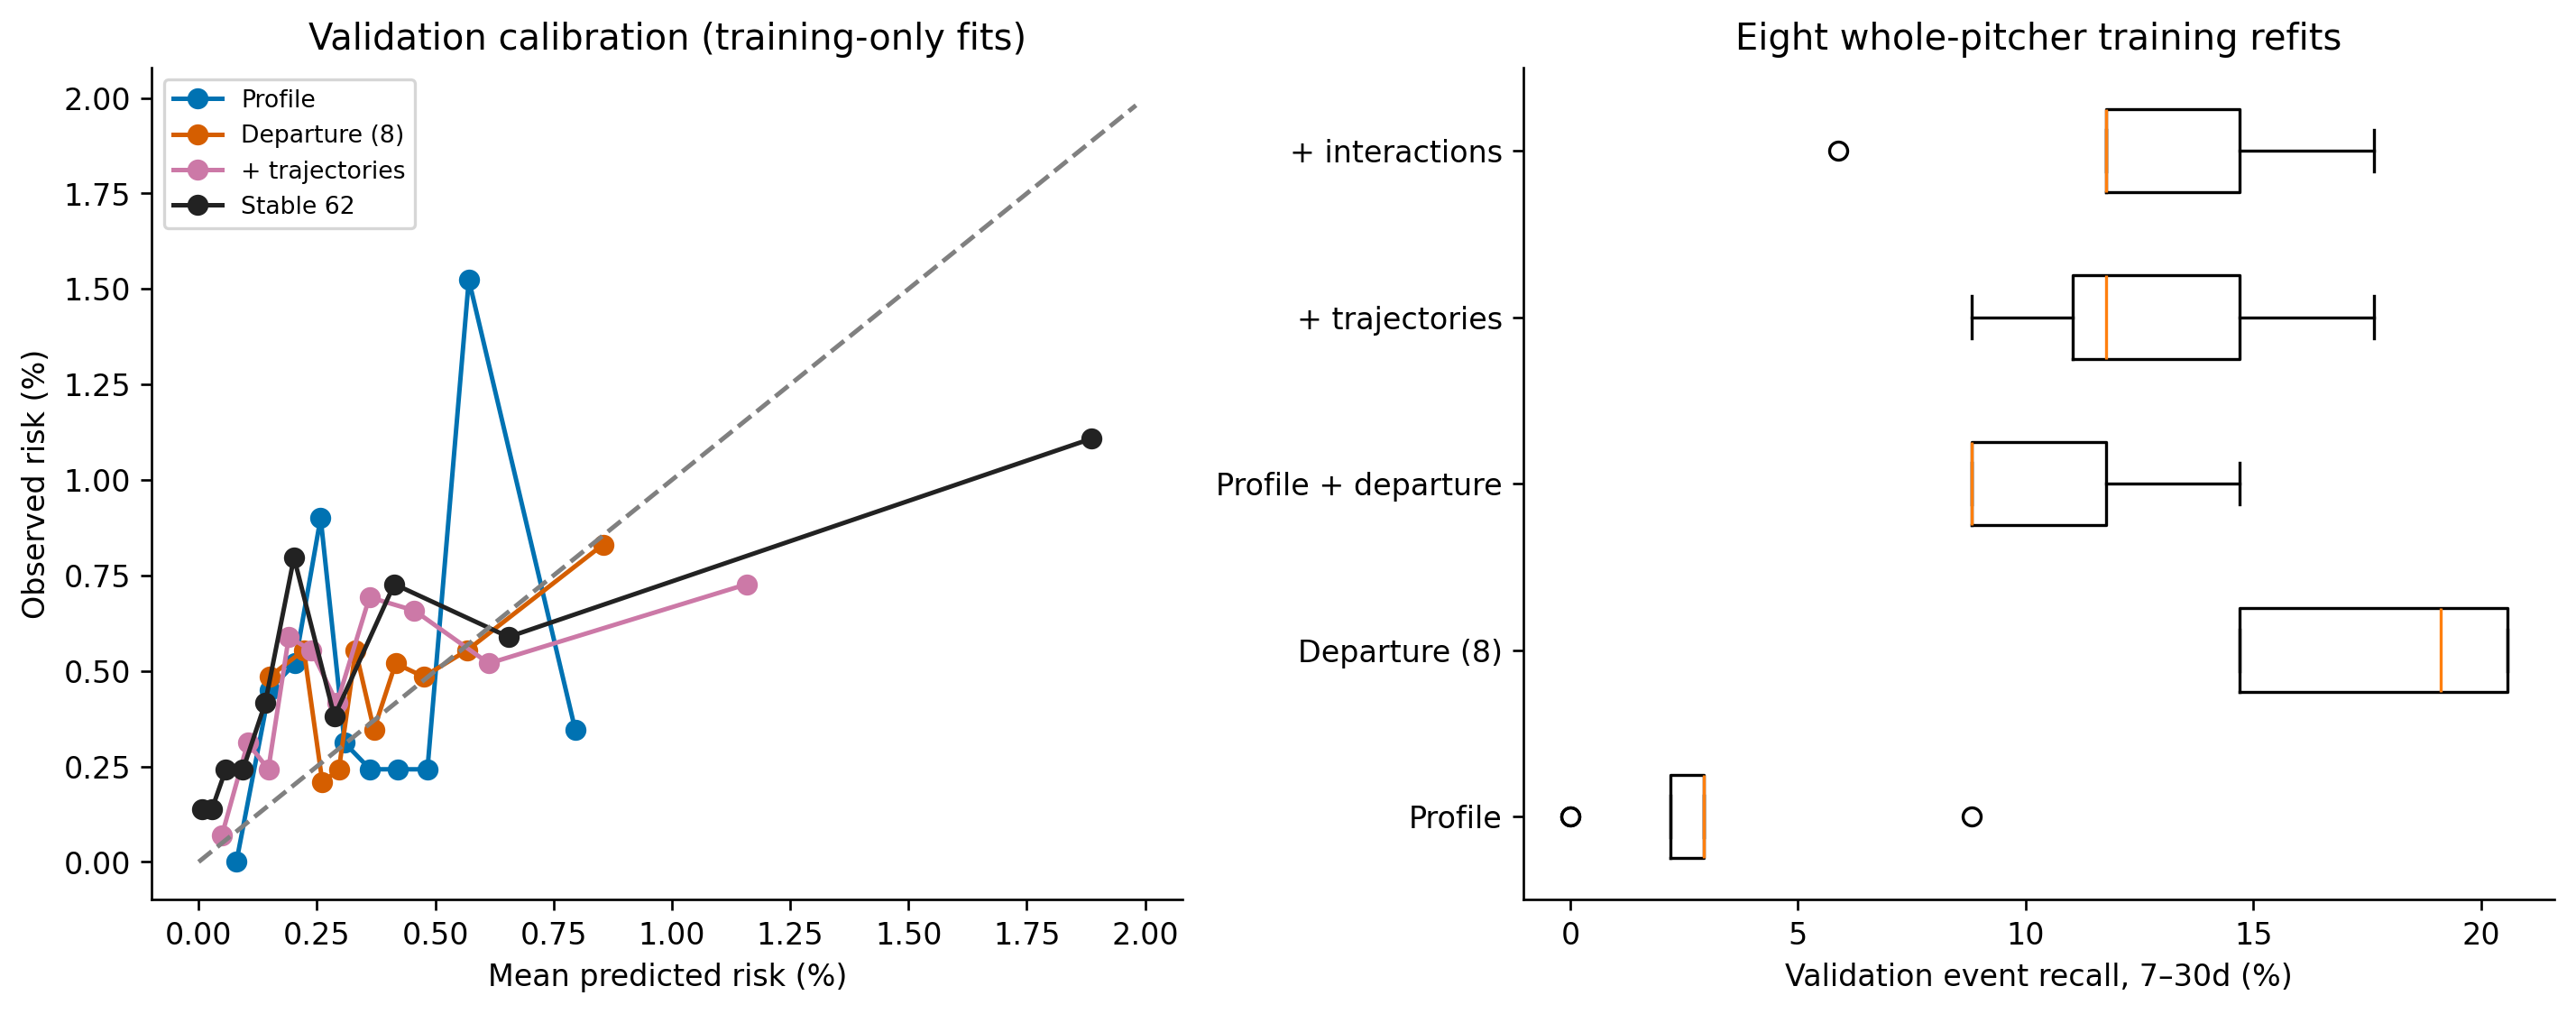

,model,feature,mean,sd,minimum,maximum,positive_fraction
140,Profile + departure + trajectory + interactions,avg_fb_velo_baseline_mean × velo_z,-0.011403,0.075830,-0.107032,0.087490,0.500
155,Profile + departure + trajectory + interactions,extension_avg_baseline_mean × extension_z,0.025781,0.075122,-0.115756,0.144131,0.750
194,Profile + departure + trajectory + interactions,release_z_sd_baseline_mean × release_z_sd_z,-0.008297,0.112673,-0.132202,0.154340,0.375


In [5]:
plot('06_calibration_and_refit_stability')
c=read_table('coefficient_stability')
display(c.loc[c.feature.str.contains(' × ')])

Eight whole-pitcher training refits show uncertain interaction directions: velocity, extension and release-variability interaction coefficients all change sign across refits. A tiny conditional AP gain is therefore insufficient evidence of a stable profile-dependent physiological relationship.

In [6]:
show('sensitivity_results', rows=40)
show('sensitivity_skips')

,sensitivity,partition,model,refit,event_denominator,rows,pitchers,positive_rows,represented_events,prevalence,...,brier_score,mean_predicted_risk,calibration_bias,pr_lift,qualifying_events,observable_events,alerted_events,injury_event_recall,median_warning_lead_days,false_alert_fraction
0,competing injuries censored,validation,Departure,True,all eligible endpoint events,26334,777,138,25,0.005240,...,0.005212,0.004339,-0.000901,1.519404,34,20,7,0.205882,12.0,0.987842
1,competing injuries censored,test,Departure,True,all eligible endpoint events,27099,782,142,28,0.005240,...,0.005215,0.004258,-0.000982,1.217224,43,28,2,0.046512,14.0,0.994092
2,competing injuries censored,validation,Profile + departure,True,all eligible endpoint events,26334,777,138,25,0.005240,...,0.005213,0.004015,-0.001226,1.616150,34,20,3,0.088235,12.0,0.990122
3,competing injuries censored,test,Profile + departure,True,all eligible endpoint events,27099,782,142,28,0.005240,...,0.005215,0.003587,-0.001653,1.621220,43,28,5,0.116279,17.0,0.988183
4,probable included,validation,Departure,True,all eligible endpoint events,28887,803,150,28,0.005193,...,0.005166,0.003994,-0.001199,1.443106,41,22,7,0.170732,12.0,0.988920
5,probable included,test,Departure,True,all eligible endpoint events,29357,803,150,30,0.005110,...,0.005087,0.003936,-0.001174,1.143363,50,29,1,0.020000,13.0,0.995228
6,probable included,validation,Profile + departure,True,all eligible endpoint events,28887,803,150,28,0.005193,...,0.005164,0.003646,-0.001547,1.705723,41,22,5,0.121951,15.0,0.988227
7,probable included,test,Profile + departure,True,all eligible endpoint events,29357,803,150,30,0.005110,...,0.005086,0.003304,-0.001806,1.688731,50,29,5,0.100000,17.0,0.989093
8,public placement date,validation,Departure,True,all eligible endpoint events,28845,802,138,25,0.004784,...,0.004760,0.003875,-0.000909,1.521132,34,21,7,0.205882,12.0,0.988904
9,public placement date,test,Departure,True,all eligible endpoint events,29329,802,140,28,0.004773,...,0.004753,0.003813,-0.000960,1.201768,43,28,2,0.046512,12.0,0.995225


,sensitivity,model,reason


Competing-event censoring and public-date timing retain the principal small-sample warning pattern. Probable inclusion changes denominators. Strict official, unseen-pitcher and role subsets are too small to establish broad robustness; subgroup observable-event denominators differ from primary all-event recall. No confirmation is claimed from incomplete 2026 data.

In [7]:
from src.injury_analysis.ucl_dynamic_reporting import validate_stage
checks=validate_stage()
display(pd.Series({'checks':len(checks),'passed':sum(x['passed'] for x in checks)}))
show('validation_checks', rows=60)

checks    48
passed    48
dtype: int64

,check,passed,detail
0,Database and primary source signatures preserved,True,NaN
1,"Prior reports, notebooks, models and frozen li...",True,NaN
2,Unique appearance keys,True,NaN
3,Unique canonical episode IDs,True,NaN
4,history_max_date is strictly prior,True,NaN
5,baseline_max_date is strictly prior,True,NaN
6,workload_max_date is strictly prior,True,NaN
7,dynamic_history_max_date is strictly prior,True,NaN
8,Primary events have valid timing and documente...,True,NaN
9,A procedure cannot support two primary episodes,True,NaN


In [8]:
display(Markdown((OUT/'summary.md').read_text()))

# UCL endpoint refinement and dynamic early warning

Completed from the interrupted schema/evidence review, reusing all completed feature-consolidation artifacts. No prior numerical stage was rerun or replaced. This is development and exploratory transfer analysis, not prospective confirmation.

## Endpoint and cohort

The primary endpoint contains **194 eligible documented UCL episodes** (98 training, 34 validation, 43 exploratory transfer, 19 descriptive 2026). Official non-procedure UCL diagnosis supports 60; the other 134 require a bounded, identifier-linked UCL procedure with compatible anatomy, no intervening MLB return, and no incompatible episode boundary. There are 221 eligible events when probable evidence is included. Twenty-two compatible forearm-to-UCL progressions were retained with explicit source adjudication. Generic elbow pain, unconfirmed forearm injury, postoperative entries and unresolved episode ambiguity are not automatically UCL outcomes.

The date is the earliest canonical reported/retroactive/effective injury proxy, never a substituted surgery date. Biological onset is generally unknown. Source retrieval occurred retrospectively; contemporaneous archived publication was not independently verified. The strict official sensitivity has only seven validation events, of which three have labeled appearances, and is underpowered.

There are 233,433 source appearances. The 30-day labeled risk sets contain 87,332 training, 28,875 validation and 29,349 exploratory-transfer appearances. Positive events represented are 59, 25 and 28; not every eligible UCL episode has a preceding MLB appearance. At 7–30 days, only 20/34 validation and 28/43 transfer events have an eligible warning opportunity. All eligible endpoint events remain in the principal recall denominator.

## Modeling and findings

At each completed appearance, fixed L2 logistic landmark models estimate first-event UCL risk over 7, 14, 21 or 30 days. These are separate horizon models, not a coherent survival curve. They preserve profile, departure-8, prior-62 and stable-62 representations. Twelve new trajectory fields and three standardized profile×departure interactions test dynamic additions. Missing values are imputed only inside training-fitted preprocessing; source data remain nullable.

The predeclared validation warning rule selected **Departure** before any new 2024–2025 predictions. It detected **7/34 validation events (20.6%)** at 7–30 days and a 5% appearance budget, versus **2/43 (4.7%)** in exploratory transfer. Conditional median first-warning lead was 12 and 14 days. These medians describe detected events only. The result does not establish dependable warning.

Profile alone had validation AP 0.00612 versus 0.00727 for departure, 0.00737 combined, 0.00769 with trajectories and 0.00789 with interactions. Paired uncertainty includes zero for the profile/departure and trajectory AP increments. The small interaction AP increment is positive under conditional validation resampling, but adds no validation warning events; training-refit uncertainty and multiple exploratory comparisons limit interpretation.

Stable-62 achieved validation AP 0.01092 (2.28× prevalence) and transfer AP 0.01846 (3.82×). Its 7–30d event warnings were 3/34 and 9/43. Previous-62 warned on 3/34 and 9/43. Better ranking and better practical warning are distinct, and transfer results must not retroactively change the selected candidate.

Adding trajectories to profile+departure left validation warnings at 3/34; exploratory-transfer warnings rose from 5/43 to 6/43. Interactions added no warnings in either period. The evidence does not justify claiming a robust incremental early-warning benefit.

Matched risk plots use 33 balanced five-outing pairs and 16 balanced calendar-window pairs, unchanged existing controls where available, and same-stratum matches only for newly eligible episodes. Whole dependency-cluster intervals account for shared case/control pitchers. Average departure risk does not show a consistent rise as injury approaches; individual paths are heterogeneous. A flat group offset is a profile association, not evidence of imminence. No latent or risk score is interpreted as tissue damage. All three interaction coefficient signs vary across the eight training refits, weakening any interpretation of the small AP increment.

## Warning burden, uncertainty and robustness

More than 98% of labeled alerts are negative for the first-event UCL outcome within 30 days in the principal departure comparison. This includes known competing first injuries, not a claim of complete medical surveillance. Unknown/censored outcomes are excluded from labeled performance, not called healthy. `operational_all_landmark_burden.csv` separately applies the frozen numeric threshold to every prospectively eligible appearance and retains unknown alert outcomes: 1,980 validation alerts include 536 unknown outcomes; 1,875 transfer alerts include 518. Numeric-threshold alert rates can drift away from 5%; retrospective top-N budgets are not deployment thresholds.

Whole-pitcher paired resampling, eight whole-pitcher training refits, endpoint expansion, strict official diagnoses, public-date timing, competing-event censoring, exclusion of the last six days, complete trajectory support, role and unseen-pitcher comparisons are reported. Subgroup analyses use explicitly identified observable-event denominators. The strict/unseen subsets are too small to establish generalization. No formal universal change point is supported by the irregular and limited event histories.

Known non-UCL first injuries are competing negatives for the primary cumulative first-event question. Suspected UCL/ambiguous arm episodes are censored. Censoring all known competitors is a sensitivity analysis. No alert may skip an intervening episode to receive credit for a later UCL event.

Endpoint specificity and the risk set changed from the previous broad Elbow/UCL analysis, so its AP and warning counts are not directly comparable to these results. The same-endpoint 30-day frozen-feature benchmarks provide the comparison here. Multi-horizon modeling has not established an independent improvement over ordinary 30-day appearance-level classification.

## Frozen next step

Keep the validation-selected departure-8 model, profile and prior-62 comparators, and all prespecified model artifacts frozen in `frozen_protocol.json`; do not retune them on transfer outcomes. Retain stable-62 as the already specified broader comparison, not a newly validated winner. Acquire a genuinely post-freeze chronological cohort with contemporaneous source snapshots, complete outcome follow-up and adjudicated UCL episodes. Use the frozen validation-derived threshold, report realized alert burden, and audit injuries and dates blind to prediction scores. Current results warrant further study, not clinical deployment or a confirmatory performance claim.

## Files

- `notebooks/ucl_dynamic/`: endpoint/cohort; models/warnings; trajectories/robustness.
- `reports/ucl_dynamic/tables/`: complete adjudication, evidence links, event opportunities, comparisons, bootstrap/refit uncertainty, sensitivities, calibration and QA.
- `reports/ucl_dynamic/figures/`: six PNG/PDF figures, numbered 01–06.
- `data/injury/analysis/ucl_dynamic/`: immutable-source derived data, predictions and fitted model caches.
- `reports/ucl_dynamic/frozen_protocol.json`: exact representations, fit signatures, validation thresholds and freeze timestamp.

Rerun/resume: `.venv/bin/python -m src.injury_analysis.ucl_dynamic_pipeline` then `.venv/bin/python scripts/run_injury_analysis_notebooks.py --suite ucl-dynamic`. Checkpoint hashes fail loudly on changed inputs. The database is opened read-only.


**Freeze:** Preserve departure-8 as the validation-selected hypothesis and all prespecified comparators and exact fit signatures. Apply the frozen numeric validation threshold without retuning to a prospectively acquired, mature post-freeze cohort. Archive sources as they become available, adjudicate outcomes blind to scores, and report unknown follow-up and realized alert burden. Do not present the current model as a clinical detector.